In [1]:
import pandas as pd

df = pd.read_csv("employee_salary_raw.csv")

df.head()

,employee_id,age,gender,department,job_role,education,experience_years,salary,joining_date,joining_year
0,E0001,39,Male,Operations,Operations Manager,Master's,12,109748.56,2014-04-08,2023
1,E0002,25,Female,HR,HR Manager,Master's,4,73882.68,2011-12-21,2021
2,E0003,34,Male,Engineering,Senior Software Engineer,Bachelor's,9,114848.01,2025-12-16,2025
3,E0004,35,Female,Operations,Operations Manager,Bachelor's,13,101785.12,2012-05-19,2024
4,E0005,34,Male,Operations,Operations Executive,Bachelor's,8,70594.25,2021-12-07,2019


In [2]:
print("Shape:", df.shape)

df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistics:")
df.describe()

Shape: (501, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   employee_id       501 non-null    object 
 1   age               501 non-null    int64  
 2   gender            501 non-null    object 
 3   department        501 non-null    object 
 4   job_role          501 non-null    object 
 5   education         501 non-null    object 
 6   experience_years  501 non-null    int64  
 7   salary            500 non-null    float64
 8   joining_date      501 non-null    object 
 9   joining_year      501 non-null    int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 39.3+ KB

Missing Values:
employee_id         0
age                 0
gender              0
department          0
job_role            0
education           0
experience_years    0
salary              1
joining_date        0
joining_year        0
dtype: int64



,age,experience_years,salary,joining_year
count,501.000000,501.000000,500.000000,501.000000
mean,31.876248,7.487026,89572.329340,2020.295409
std,5.282864,4.522646,28513.538003,2.888003
min,21.000000,0.000000,27123.490000,2016.000000
25%,28.000000,4.000000,66229.832500,2018.000000
50%,32.000000,8.000000,89003.540000,2020.000000
75%,36.000000,12.000000,113818.565000,2023.000000
max,43.000000,15.000000,161187.940000,2025.000000


In [3]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing salary with median salary
df["salary"] = df["salary"].fillna(df["salary"].median())

# Clean text columns
df["department"] = df["department"].str.strip().str.title()
df["job_role"] = df["job_role"].str.strip().str.title()

# Check cleaning
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
employee_id         0
age                 0
gender              0
department          0
job_role            0
education           0
experience_years    0
salary              0
joining_date        0
joining_year        0
dtype: int64

Duplicate rows:
0


In [4]:
df["experience_level"] = pd.cut(
    df["experience_years"],
    bins=[-1, 2, 5, 10, 50],
    labels=["Entry", "Junior", "Mid", "Senior"]
)

df[["experience_years", "experience_level"]].head(10)

,experience_years,experience_level
0,12,Senior
1,4,Junior
2,9,Mid
3,13,Senior
4,8,Mid
5,7,Mid
6,5,Junior
7,4,Junior
8,14,Senior
9,2,Entry


In [5]:
df["experience_level"] = pd.cut(
    df["experience_years"],
    bins=[-1, 2, 5, 10, 50],
    labels=["Entry", "Junior", "Mid", "Senior"]
)

df.head()

,employee_id,age,gender,department,job_role,education,experience_years,salary,joining_date,joining_year,experience_level
0,E0001,39,Male,Operations,Operations Manager,Master's,12,109748.56,2014-04-08,2023,Senior
1,E0002,25,Female,Hr,Hr Manager,Master's,4,73882.68,2011-12-21,2021,Junior
2,E0003,34,Male,Engineering,Senior Software Engineer,Bachelor's,9,114848.01,2025-12-16,2025,Mid
3,E0004,35,Female,Operations,Operations Manager,Bachelor's,13,101785.12,2012-05-19,2024,Senior
4,E0005,34,Male,Operations,Operations Executive,Bachelor's,8,70594.25,2021-12-07,2019,Mid


In [6]:
# 1. Average Salary
print("Average Salary:", df["salary"].mean())

# 2. Minimum Salary
print("Minimum Salary:", df["salary"].min())

# 3. Maximum Salary
print("Maximum Salary:", df["salary"].max())

# 4. Average Salary by Department
print("\nAverage Salary by Department:")
print(
    df.groupby("department")["salary"]
    .mean()
    .sort_values(ascending=False)
)

# 5. Average Salary by Experience Level
print("\nAverage Salary by Experience Level:")
print(
    df.groupby("experience_level", observed=True)["salary"]
    .mean()
)

# 6. Average Salary by Job Role
print("\nAverage Salary by Job Role:")
print(
    df.groupby("job_role")["salary"]
    .mean()
    .sort_values(ascending=False)
)

# 7. Average Salary by Education
print("\nAverage Salary by Education:")
print(
    df.groupby("education")["salary"]
    .mean()
    .sort_values(ascending=False)
)

Average Salary: 89585.54372
Minimum Salary: 27123.49
Maximum Salary: 161187.94

Average Salary by Department:
department
Data           103426.802759
Engineering     94304.052500
Finance         92041.842727
Marketing       87225.952432
Sales           86155.932537
Operations      83787.809136
Hr              83735.191200
Name: salary, dtype: float64

Average Salary by Experience Level:
experience_level
Entry      54193.582473
Junior     69601.347895
Mid        91448.512697
Senior    120252.916938
Name: salary, dtype: float64

Average Salary by Job Role:
job_role
Data Scientist              114418.488065
Senior Software Engineer    105214.289600
Finance Manager              99484.345833
Sales Manager                95962.473947
Marketing Manager            90850.600000
Data Analyst                 90698.061071
Operations Manager           90435.573500
Software Engineer            88058.180238
Hr Manager                   87722.612368
Financial Analyst            85468.100000
Marketing 

In [7]:
print("Employees by Department:")
print(df["department"].value_counts())

print("\nEmployees by Experience Level:")
print(df["experience_level"].value_counts())

print("\nEmployees by Education:")
print(df["education"].value_counts())

Employees by Department:
department
Operations     81
Finance        77
Hr             75
Marketing      74
Engineering    68
Sales          67
Data           58
Name: count, dtype: int64

Employees by Experience Level:
experience_level
Senior    160
Mid       152
Junior     95
Entry      93
Name: count, dtype: int64

Employees by Education:
education
Bachelor's    276
Master's      191
PhD            33
Name: count, dtype: int64


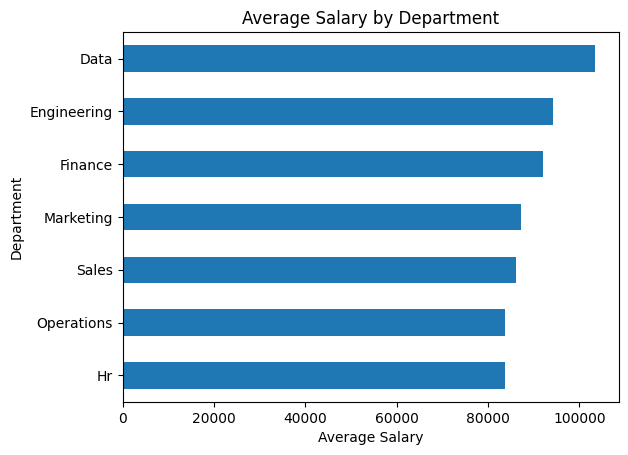

In [8]:
import matplotlib.pyplot as plt

# Salary by Department
df.groupby("department")["salary"].mean().sort_values().plot(kind="barh")

plt.title("Average Salary by Department")
plt.xlabel("Average Salary")
plt.ylabel("Department")
plt.show()

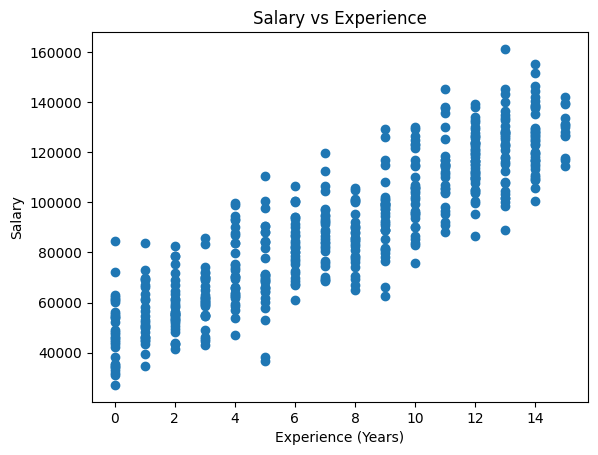

In [9]:
# Salary vs Experience

plt.scatter(df["experience_years"], df["salary"])

plt.title("Salary vs Experience")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.show()

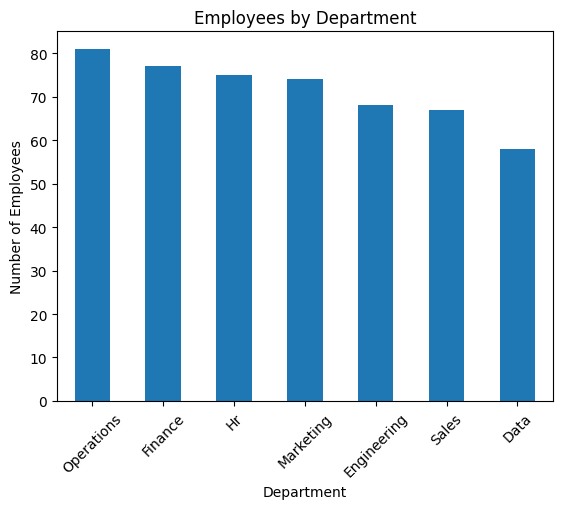

In [10]:
# Employees by Department

df["department"].value_counts().plot(kind="bar")

plt.title("Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.show()

In [11]:
df.to_csv("employee_salary_clean.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [12]:
df.shape

(500, 11)

In [13]:
df.head()

,employee_id,age,gender,department,job_role,education,experience_years,salary,joining_date,joining_year,experience_level
0,E0001,39,Male,Operations,Operations Manager,Master's,12,109748.56,2014-04-08,2023,Senior
1,E0002,25,Female,Hr,Hr Manager,Master's,4,73882.68,2011-12-21,2021,Junior
2,E0003,34,Male,Engineering,Senior Software Engineer,Bachelor's,9,114848.01,2025-12-16,2025,Mid
3,E0004,35,Female,Operations,Operations Manager,Bachelor's,13,101785.12,2012-05-19,2024,Senior
4,E0005,34,Male,Operations,Operations Executive,Bachelor's,8,70594.25,2021-12-07,2019,Mid


In [15]:
from google.colab import files

files.download("employee_salary_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import pandas as pd

df = pd.read_csv("employee_salary_clean.csv")

with open("employees_insert.sql", "w", encoding="utf-8") as f:
    for _, row in df.iterrows():
        values = []

        for col in df.columns:
            value = row[col]

            if pd.isna(value):
                values.append("NULL")
            elif col in ["age", "experience_years", "joining_year"]:
                values.append(str(int(value)))
            elif col == "salary":
                values.append(str(float(value)))
            else:
                value = str(value).replace("'", "''")
                values.append(f"'{value}'")

        f.write(
            "INSERT INTO employees VALUES ("
            + ", ".join(values)
            + ");\n"
        )

print("SQL file created successfully!")

SQL file created successfully!


In [17]:
from google.colab import files
files.download("employees_insert.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>